# 4 — How the studies changed our understanding

## A retrospective of the alternatives, their tests and the evidence that survived

Read this chapter after [the research map](00_research_guide.ipynb), or use it as a
standalone account of why the project made its major decisions. The question was whether
hippocampal cue activity contains information about a subsequent **path beyond start and
goal**. Endpoint recovery, a binary path component, and full ordered-route prediction
are different tasks. H1a concerns incremental path information; H1b concerns reproducible
low-dimensional organization of that information. Neither is established by endpoint
classification or a visually attractive latent cloud.

All numerical results and seven attached figures here come from **accepted historical
exploratory studies** in this repository. They can be read offline without a kernel.
The two optional code cells use invented lists to teach target construction and temporal
pairing; they access no recordings and fit nothing. No historical model is re-executed,
and these figures are not current compact-source training curves. Study links identify
provenance; the explanations needed to interpret the results are in this notebook.

The research did not consist of one steadily improving benchmark. It changed targets,
support requirements and models while investigating alternative explanations. The
important output is therefore a chain of bounded conclusions, including negative results,
not a ranking of scores collected on different datasets.

## 1. First establish which experiment a number belongs to

| Experiment family | Real sources and selected units | Constructed evaluation / question |
| --- | --- | --- |
| September endpoint sampler/checkpoint study | 195 units / 58 sessions; 12,288 training / 3,265 development sources | 480/240 rows at standard budget, 30 ordered pairs; three computational seeds |
| V9 and September7 Track A/B; later frozen-readout diagnosis | 29 units / 7 sessions; 82 training / 22 development sources | Fixed 4→3 interior component; Track A/B and decoder studies enumerate 24 absent + 6 present combinations |
| September7 Track C supported target | 43 units / 11 sessions; 267 training / 52 development sources | Per-unit real-trial increment beyond endpoint/time/duration, with a different supported component |
| September8 preprocessing / matched PCA | 49 distinct unit IDs / 13 sessions; 147 training / 41 development sources across five endpoint panels | Within-endpoint binary component, first-second rates; exact development products per panel |
| September25 joint-path / October5 cue-bin readouts | 29 units / 7 sessions; 82/22 sources | New matched joint study: 128 training rows, 30 weighted development combinations; later readouts reuse its encoders |
| October7 direct endpoint heads | 195 units / 58 sessions; 12,288/3,265 sources | 480/240 rows; separate pair/start/goal heads and matched cue/joint encoders |
| October23 fresh-input package | 27 units / 10 sessions; 1,415/551 sources | Stricter contributor separation and complete support; separate cue-only assay, summarized in Chapter 0 |

Development sources were historically exposed. Seeds vary assembly/optimization, not
animals or independent biological folds. Session counts are not animal counts. The same
29-unit cohort can still have different assemblies, scalers and optimization recipes;
its scores are not automatically matched across studies. The newer compact-source route
also changes timestamp precision and applies its own selection rules. Neither its input
archive nor its reproducible package retroactively validates the historical conclusions.

## 2. Turning movement into a target: a graph is a measurement choice

The recorded behavior is an ordered sequence of positions. The maze has a broad floor
around pillars, so simply treating every neighboring floor-grid cell as a decision
produced fragmented route signatures. The accepted V6 representation instead used
**nine node/plaza regions, twelve corridor regions and twenty-four directed corridor
components**, defined from static geometry. These are analysis regions, not claimed
discrete brain states or an implemented cognitive-choice model.

The actual mapping assigns samples to static coordinate bands, groups successive region
samples into runs, and infers corridor direction using neighboring node evidence first,
then net corridor progress where available. Weaker one-neighbor direction evidence is
flagged separately. For a horizontal corridor, normalized position is
`(x − x_min)/(x_max − x_min)`; the vertical counterpart uses y. Lateral deviation is
retained. This is not arbitrary-path arclength or a full HMM map matcher. Unknown gaps
are not filled with shortest paths: doing so could invent the very component being tested.

The target asks whether a selected directed component occurs **anywhere among the interior
corridor runs, after excluding the first and last**. It does not mean the middle time bin or one
central ordinal run. `D_N_R_T__N_R_M` means the right upper-to-middle direction. Reverse
travel is a different component. A later supported target, `D_N_C_M__N_C_B`, uses the
central middle-to-bottom direction. Selection used behavioral support, not a search for
the neural score that looked best.

**Worked schematic, not a recorded trial:** let `e` denote the chosen direction and
`a,b,c,d` other corridor traversals. `[a,e,b,c]` is interior-present; `[e,a,b,c]` is
interior-absent despite traversing `e` somewhere. `[a,e]` has no interior corridor run.
If mapping is incomplete or direction unknown, absence is not established. The distinction
was consequential: 51/185 old fixed-4→3 “absent” paths contained the component outside
the interior. That is a target-definition issue, not proof of a clock or truncation bug.

Implementation: [`finalize_trial` and direction/mapping routines](../scripts/place195_v6_graph_support_audit.py)
retain raw coordinates, run records, complete-mapping flags and component sets.
[V6–V9 methods and decisions](../docs/reports/place195-v6-v9-autoresearch-20260906.md)
describe the rejected graph alternatives and support audits.

In [1]:
# Software illustration only: already-mapped symbolic corridors, no lab data.
def schematic_component_label(corridor_runs, target, *, complete):
    if not complete:
        return "unknown"
    interior = corridor_runs[1:-1] if len(corridor_runs) >= 3 else []
    return "present" if target in interior else "absent"

for sequence, complete in [(["a", "e", "b", "c"], True),
                           (["e", "a", "b", "c"], True),
                           (["a", "e"], True),
                           (["a", "e", "b"], False)]:
    print(sequence, "→", schematic_component_label(sequence, "e", complete=complete))
# This teaches the membership rule; it does not replace mapping, QC or eligibility.

['a', 'e', 'b', 'c'] → present
['e', 'a', 'b', 'c'] → absent
['a', 'e'] → absent
['a', 'e', 'b'] → unknown


## 3. Why more pseudotrials did not solve limited source support

Within class `y`, the construction samples one source block from each session's empirical
pool. Its conditional distribution is a product, `Q(x|y) = product_s Q_s(x_s|y)`.
This encodes a cross-session independence assumption for assembly. It preserves each
selected source block but cannot estimate cross-session noise correlations that were
never recorded together. With only a few sources, an accidental class difference in one
session can be repeated in thousands of constructed rows.

Track A asked whether poor transfer reflected Monte Carlo assembly noise, scaling or
finite-source support. It enumerated the **exact development product**: 24 absent and
6 present combinations, each class assigned half the evaluation mass. Thus an absent
row has weight `0.5/24`, and a present row `0.5/6`. Exhaustion removes randomness from
which available combinations are evaluated; it does not create independent observations.
The 290-feature whole-cue development matrix had rank 9 by construction. That rank is
about a tiny source-product matrix, not the hippocampus's intrinsic dimensionality.

For whole-cue vectors, the product model has blockwise conditional covariance; mixing
two classes adds a between-class mean term of rank at most one. Pooled-bin PCA also
mixes common cue times, so its covariance need not obey that same rank-one description.
Track A computed exact training moments and a ridge reference to distinguish true
finite-pool structure from noise introduced by sampling a finite number of pseudorows.
Ridge stabilized near **47.9% BA**, rather than becoming reliable with more synthetic
draws. Source subsets and session-block influence mattered more.

The study also varied rows per class and normalized the logistic penalty with row count.
Otherwise, duplicating examples changes both assembly coverage and effective regularization.
Known-truth Gaussian controls made the failure concrete: even with zero population signal,
finite sampled source pools can yield excellent or inverted empirical-product decoding.
The true distribution still has 50% BA for a frozen classifier. Simulation established
this possible failure mode; it did not prove the real neurons have zero signal.

[Track A/B/C frozen design](../docs/reports/path-generalization-prefit-20260907.md) and
[completed corrected findings](../docs/reports/path-generalization-completed-state-20260907.md).

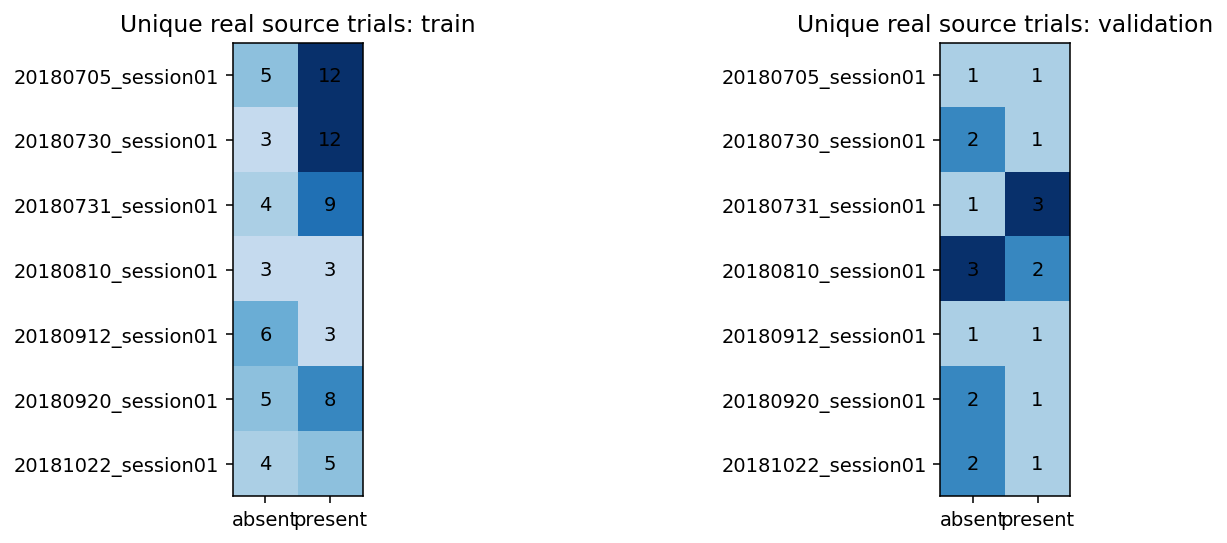


**Figure 1 — Which pools can actually vary?** Public October5 support presentation for
the fixed 4→3 interior component: 29 units / 7 sessions, 82 training sources (30 absent,
52 present) and 22 exposed-development sources (12/10). The joint study used 128 balanced
training rows and 30 development products (24/6, half weight/class). Eight development
session×class pools are singletons. Counts have no decoder or uncertainty interval.
**Read it:** a singleton cannot reveal unseen source variability when repeatedly drawn.
Source: [accepted study and source table](../docs/reports/cebra-cue-time-readout-20261005/README.md),
`figures/source_support.png`. This describes support, not independent replication.

## 4. Source transfer versus new combinations: Tracks B and C

Track B crossed five assembly seeds with five optimizer seeds for each Time/Behavior
encoder, then bounded dimension, row-count and update-budget sensitivities. It separated
two questions: can a model handle a new combination of familiar training sources, and
can it handle different source trials? Frozen checkpoints achieved mean BA **99.25%
Time / 99.77% Behavior** on new mixtures of training sources. Across the other source
pool, factorial means were only **24.92% / 35.17%**; own-training BA was 100%.

This weakens “it merely memorized the exact sampled combinations” as the full explanation.
It localizes the failure to transfer across source pools, but does not identify whether
source scarcity, history, drift, target association or encoder choice caused it. More
dimensions, rows or updates did not provide a consistent rescue. The corrected maximum
family tail was **19/21**; a floating-point equality was explicitly counted inclusively.
Changing the inferential bookkeeping did not change fitted models or predictions.

Track C asked a complementary question without stitching a population. For each unit,
it compared a real-trial baseline using endpoint-pair intercepts, trial index and cue
duration with an augmented model adding log-transformed cue count/exposure. Full-cue
rate here differs from the later fixed-first-second preprocessing inputs. Training
eligibility and target support were declared before neural fitting; effects were
aggregated within session, then equally across sessions. Ordinary and temporal-stratum
nulls permuted coherent source labels shared across units and repeated both fits.

For the supported interior target, 43 units / 11 sessions with 267/52 sources gave mean
loss improvement **0.003860 nats**, but three-target family tails were about **0.475
ordinary / 0.436 temporal**. This was not convincing incremental cue-rate evidence.
Per-unit results are a complementary assay, not an individual-neuron significance gate
that a valid population analysis must pass. Temporal shuffling also does not guarantee
all history confounds have been controlled.

[Study index and correction ledger](../docs/professor_updates/path_generalization_20260907/README.md).

## 5. Could preprocessing make a source-limited path assay reliable?

The September8 study changed to the supported central component across five endpoint
panels, with 49 unit IDs / 13 sessions and 147/41 sources. Panel eligibility used recorded
behavior/QC and existing development class support; it was not a pristine training-only
cohort discovery. The model predicted one binary label within each endpoint pair, then
averaged endpoints equally. Endpoint identity therefore stayed fixed within each model.

The controlled interventions were 1/2/5 time bins over the same first second, raw-rate/
square-root/log1p features, and standard versus variance-floor scaling. The first 18
recipes used average-loss L2 strength `λ=.1`; two additional strengths were examined
only for the source-CV-selected representation. All 20 recipes and the two-stage
selection were retained. Here `C=1/(λ × training_rows)` kept the average-loss penalty
fixed as row count changed; it is not interchangeable with a study that holds `C` fixed.

| Feature choice at λ=.1 | Training log loss | Source-held-out CV loss |
| --- | ---: | ---: |
| One-second raw rate, standard scale | 0.2728 | 0.7058 |
| One-second raw rate, variance floor | 0.2896 | 0.6193 |
| Five bins, raw rate, standard scale | 0.0947 | 1.1431 |

More temporal features fitted training better and transferred worse. This supports a
finite-source estimation concern, not absence of temporal coding: the richer model
also changes parameter count and regularization geometry. One time bin still leaves
one input per unit. Invertible square-root/log transforms change linear accessibility,
not necessarily information in the Shannon sense. The variance floor is a numerical
prior, not a verified neural noise model.

The frozen stronger-penalty recipe reached **55% BA** and **+0.02858 nats** relative to
constant-.5 loss, but only **2/5** endpoint panels had positive loss skill. Removing
6→1 changed the remaining mean to **−0.03787**. Declared null tails ranged **0.139–0.356**;
source-resampling sensitivities crossed zero. Seventeen of 28 development pools were
singletons. Better probability predictions within this comparison did not establish
broad robust prospective coding.
[Full preprocessing record](../docs/reports/path-preprocessing-autoresearch-20260908.md).

## 6. What did the matched PCA comparison actually isolate?

The separate matched study used the same five endpoint panels, source-safe rows, first-
second rates and training-only variance-floor scaling. The PCA arm alone added a
training-fitted full-SVD projection reaching 90% variance, without whitening. Both arms
selected from the same `λ=.01/.1/1` grid using training-source CV; both selected `λ=1`.
PCA retained 2, 9, 2, 7 and 13 components across panels. These counts describe the
linear variance needed for those inputs, not percent path information preserved.

| Endpoint | Raw loss | PCA loss | Raw − PCA | Raw/PCA BA |
| --- | ---: | ---: | ---: | ---: |
| 2→1 | 0.694618 | 0.694618 | 0.000000 | 50% / 50% |
| 3→1 | 0.775618 | 0.771723 | 0.003895 | 25% / 25% |
| 4→1 | 0.643258 | 0.642561 | 0.000697 | 50% / 50% |
| 5→1 | 0.810584 | 0.785025 | 0.025559 | 50% / 50% |
| 6→1 | 0.398740 | 0.393778 | 0.004963 | 100% / 100% |

Mean raw/PCA losses were **0.664564/0.657541**, a **0.007023-nat** paired advantage for
PCA, with the same 55% mean BA. Probability quality changed without improved threshold
accuracy. Positive paired improvement can occur even when both arms remain worse than
`log(2)` in an endpoint. Paired fixed-selection source-resampling percentiles were
**−0.011444 to +0.023426**; they are sensitivities, not biological or selection-adjusted
confidence intervals. Arm-versus-baseline label-null tails are not PCA-superiority tests.

This fills a specific fair-comparison gap. It neither reproduces the older 83% endpoint
PCA score nor establishes H1. The λ=1 raw probabilities exactly reproduced the accepted
anchor; that demonstrates numerical compatibility, not independent replication.
[Matched study, all recipes and controls](../docs/reports/path-pca-matched/report.md).

## 7. Endpoint ablations: did the contrastive task match the question?

The September endpoint investigation returned to 30 start–goal conditions in the
195-unit/58-session cohort. CEBRA-Behavior uses known condition labels to define positive
pairs; ordinary same-pair positives can mix early and late cue bins. Matching both pair
and bin asks the encoder to associate examples with the same condition **at the same
cue time**. Time positives instead follow adjacent bins in the same constructed row.
Neither construction makes the overall pipeline label-free, because assembly already
uses labels.

| Matched or declared intervention | Observed three-seed development pair accuracy | Conclusion that survives |
| --- | --- | --- |
| Same temperature .3 / 250 updates: ordinary Behavior → same-pair/same-bin positives, global negatives | 53.06% → 83.33% | Positive pairing matters for this endpoint representation |
| Same same-bin-positive recipe, 250 → 3,000 updates | 83.33% → 64.86% | More optimization is not automatically better transfer |
| Original Time, 250 → 1,000 updates | 69.72% → 51.67% | A lower objective can coexist with worse readout utility |
| At 3,000 updates: grouped-bin references with global versus same-bin negatives | 68.47% versus 59.58% | Negative time matching was not uniformly helpful |
| Time-matched recipe, 16 → 64 training rows/pair | 59.58% → 81.53%; PCA 83.61% → 84.86% | Additional construction coverage helped this recipe |

The row increase used the same 12,288-source pool but raised mean distinct contributors
from **10,889 to 12,279**. It was not pure optimization or new biological N. Requested
quarter/half source pools actually contained 3,777/6,551 sources because each required
pool retained at least one. Their source-budget curves therefore are not universal
scaling laws. A strict chronological 75/25 split supported all 30 classes in only 1/58
sessions; a weaker within-condition chronological sensitivity could not repair that.

The common PCA readout gave 83.61% at `C=.01`; the old 82.50% atlas PCA reference used
`C=1`. A cross-entropy neural follow-up also did not provide a general cure: binwise CE
reached 20.00% at 3,000 updates; 64 rows/class reached 49.03%; weight decay .1 collapsed
that recipe to 3.33%. These bounded recipes do not rule out all CE models or moderate
regularization. Favorable early checkpoints were descriptive findings on exposed data,
not independently validated selections.
[Endpoint investigation](../docs/reports/start-goal-autoresearch.md).

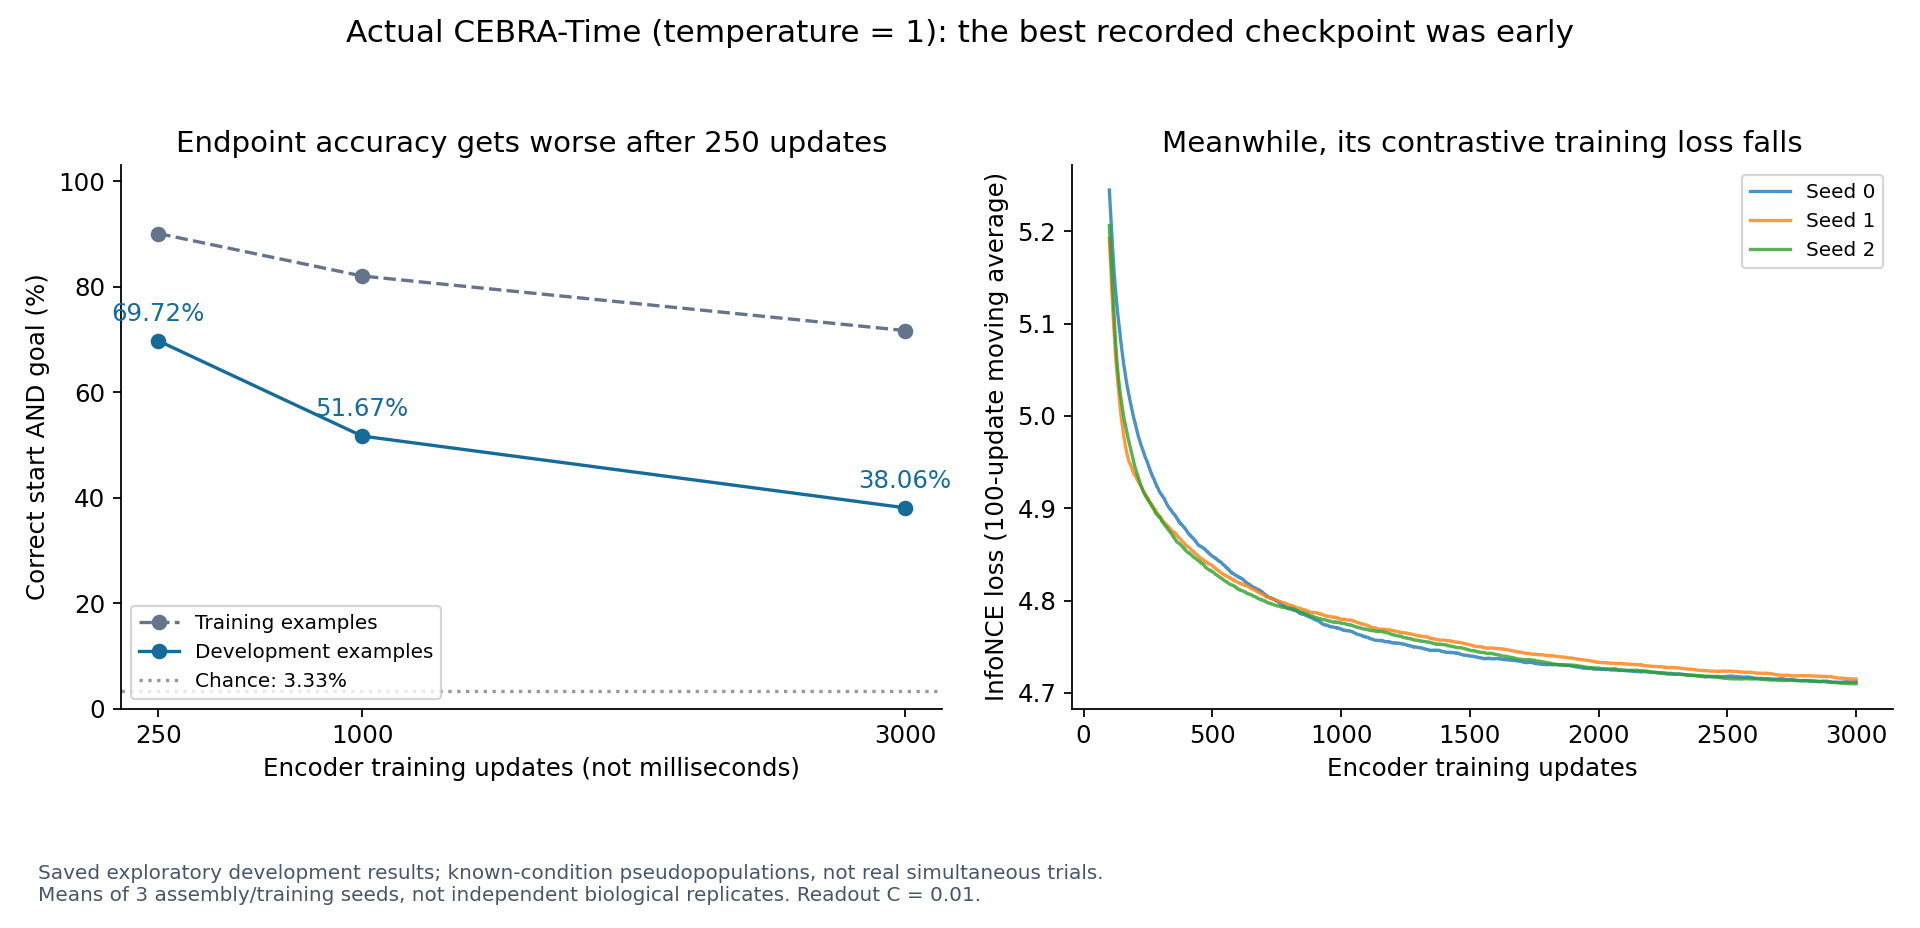


**Figure 2 — The model is optimizing, but useful prediction can deteriorate.** Actual
saved September endpoint CEBRA-Time training-loss traces and checkpoint readout accuracy,
not a schematic or current-model trace. Cohort: 195 units / 58 sessions; 12,288/3,265
training/exposed-development sources; standard 480/240 conditional rows. Three
computational seeds; pair30 whole-cue readout, ten 100-ms bins, common logistic `C=.01`.
Development accuracy declines from 69.72% at 250 updates to 51.67% at 1,000 and 38.06%
at 3,000 as contrastive loss falls. Curves are not biological uncertainty. **Read it:**
optimization success and transferable task information need different diagnostics.
Extracted unchanged from the public [endpoint teaching report](../docs/professor_updates/start_goal_20260907/endpoint-research-report.html),
September13 presentation addendum based on saved metrics/losses; no new fits here.

## 8. Can a 3D picture tell whether the representation is good?

The saved atlas describes models from the September endpoint/V9 studies, **not the
October7 cue/joint endpoint pair**. A bin point is one constructed population at one
100-ms cue bin. For an eight-coordinate encoder, a whole-cue point instead has 80
features. All three-dimensional display bases were fitted to training features and
applied unchanged to development; native three-coordinate models are identified
separately. Development energy is measured relative to the training mean.

Early same-bin Behavior decoded endpoints at **83.33%**, yet its train-fitted 3D bin
view retained only **56.3–64.2%** of development energy across seeds. Its full-space
versus projected distance correlations were **.712–.762**, and only about **44–53%** of
sampled top-ten neighbors survived. After 3,000 updates, energy retention fell to
**39.5–42.2%** while decoding fell to **64.86%**. Greater spread over dimensions did
not mean better task representation.

Early Time retained **95.2–98.9%** in 3D yet decoded less well at **69.72%**. V9 Time-8
and Behavior-8 appeared structured while original development BA remained **44.27% /
41.41%**. Normalization and supervised class attraction are competing explanations for
arcs, shells or lobes. Neither dimensional compression nor visual simplicity proves
topology, an attractor, biological trajectories or H1b.

Participation ratio, `(sum eigenvalues)^2/sum(eigenvalues^2)`, summarizes how evenly
linear variance occupies dimensions. It is not a unique intrinsic-manifold estimator.
A good figure must identify its points, projection, split, lost information and repeated
sources before interpreting its shape.
[Atlas methods and quantitative diagnostics](../docs/reports/cebra-latent-atlas-results-20260924.md).

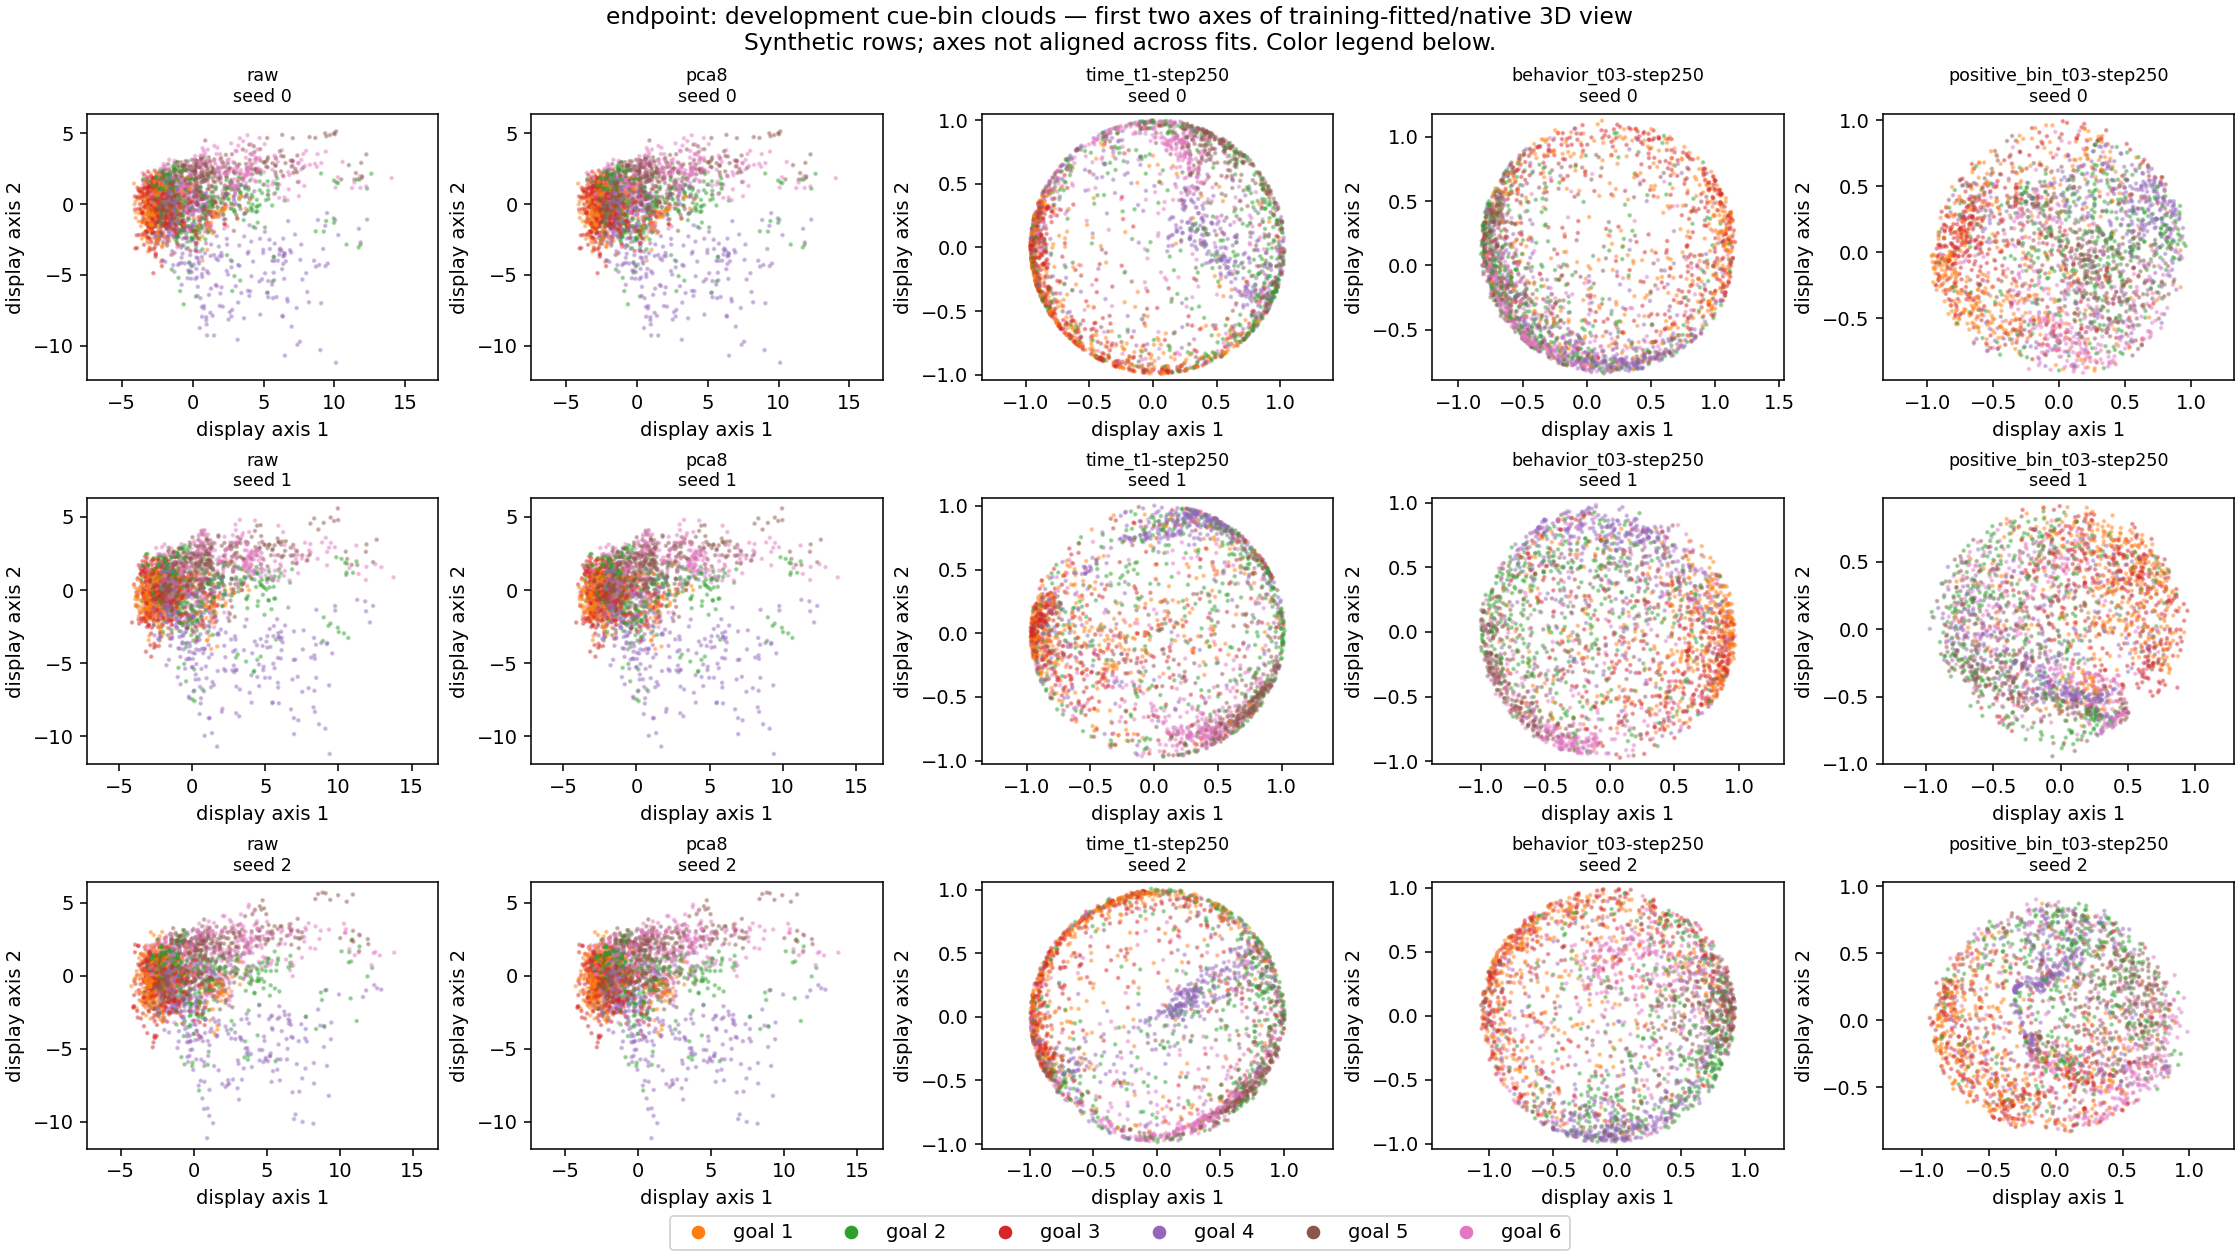


**Figure 3 — See the cloud and what the display discards.** Accepted September endpoint
development projections, raw/PCA/Time/Behavior across seeds 0–2, colored by goal. Each
point is one 100-ms population bin from a conditional pseudorow; 195 units / 58 sessions,
12,288/3,265 available train/development sources, 480/240 rows per standard seed. Display
PCA is fitted on training features, not these development points. Coordinates are
descriptive; no decoder or uncertainty interval is fitted by this figure. Existing
readout scores/projection fidelity are explained above. **Read it:** a compact shape
can have poorer prediction than a less faithfully displayed representation. Extracted
unchanged from the public [atlas review](../docs/reports/cebra-latent-atlas/review.html);
not October7 joint-endpoint geometry and not a simultaneous neural trajectory.

## 9. Was the path decoder simply too weak or too regularized?

The frozen-decoder study reused 50 Time/Behavior encoders: five assembly seeds × five
optimizer seeds per objective, on the 29-unit fixed-4→3 cohort. Eight readout recipes
varied scaled/unscaled logistic models, cosine kNN and RBF-SVM. Every recipe used the
same features for a given encoder. This tests readout accessibility of **those fixed
features**, not whether another encoder could learn a better representation.

Time's strongest nonlinear mean BA was **37.33%** versus original logistic **24.92%**;
Behavior's was **35.67%** versus **35.17%**. Neither met the declared above-chance
BA/AUROC criterion. PCA+scaled RBF reached **77.50% BA / .829 AUROC** against its
logistic **42.92% / .157**, an informative descriptive control. The first study had
no matched PCA null, so its CEBRA null could not certify that apparent PCA success.

The next diagnosis kept observed encoders/features fixed and tested logistic
`C=.001,.01,.1,1,10,100`, plus nine RBF `C × gamma` settings. For Time, weakening
regularization from `.001` to `100` changed training BA **97.63→100%**, development
BA **30.92→24.25%**, and loss **.781→5.330**. Larger weights produced more confident
errors. The expanded SVM grid reached at most **50% mean Time BA / 49.83% Behavior**,
with poor AUROC. Thus excessive decoder regularization or the original bandwidth alone
was not supported as the main explanation in this tested family.

Confidence was isolated by dividing saved logistic margins by positive temperature:
Time loss improved **2.6448→.8110** at `T=10`, with **identical BA and AUROC**. Positive
scaling leaves ordering and the zero-margin boundary intact. This is why a loss gain
need not mean better discrimination. No development-selected threshold or sign reversal
was used to rescue below-chance predictions.

New anchored nulls gave raw/PCA family tail **15/21**, joint family **19/21**, and fixed
PCA-center tail **7/21**. Those statistics concern assembly0 (and CEBRA optimizer0),
not the five-/25-run means; they neither establish nor directly test the 77.5% mean as
a superiority claim. Eight of 22 deletion checks were inestimable. The supported
conclusion is failed source transfer for these pipelines, not zero latent information
or inherent unsuitability of CEBRA for future-path questions.
[Frozen readouts](../docs/reports/cebra-decoder-autoresearch-20260924.md) ·
[regularization/kernel/confidence diagnosis](../docs/reports/cebra-hyperparameter-diagnosis-20260924.md).

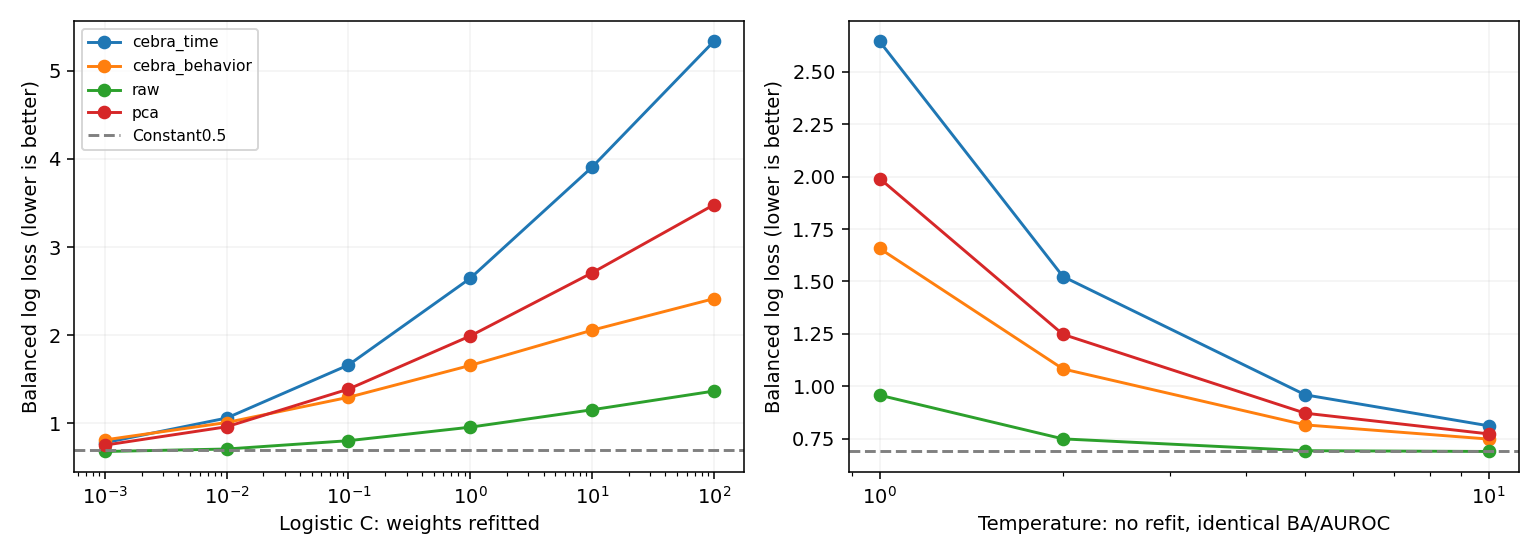


**Figure 4 — Two routes to a lower probability loss.** Fixed 4→3 interior-component
cohort: 29 units / 7 sessions; 82 training / 22 exposed-development sources; standard
128 training rows and exact 24/6 development products weighted half/class. Whole cue
is ten 100-ms count bins, 290 raw or 80 PCA/CEBRA features. Left varies fitted logistic
penalty; right rescales existing margins without changing classification/ranking.
CEBRA summaries cover 25 computational runs/objective; raw/PCA five assemblies. No
biological confidence intervals. **Read it:** only the right intervention guarantees
unchanged BA/AUROC, so distinguish confidence from recovered discriminative signal.
Exact public image from [the diagnosis](../docs/reports/cebra-hyperparameter-diagnosis-20260924.html).

## 10. Joint training: how was navigation aligned without inventing a trajectory?

The September25 study asked whether broader encoder exposure improves a **cue-only**
readout. It compared cue/broader × Time/Behavior with paired initialization, the same
1,000 updates, hidden32/output8, cosine temperature1, Adam `3e−4`, batch256. Training
sources alone supplied navigation; decoder fitting and development prediction still
used the original first-second cue. This avoids giving the decoder the later movement
whose component it predicts.

The implementation is explicit. Ripple marker times delimit cue start, cue end/navigation
start, and navigation end. Each source retains all complete native **100-ms count bins**
from its navigation interval. Final partial navigation bins are excluded and audited.
These inputs are counts, not rates divided by exposure; masks preserve which unit block
was recorded. The cue scaler, fitted on pooled assembled training cue bins, also scales
navigation. No development navigation is used to fit or choose an alignment.

Navigation duration differs across sources. Storage is ragged; there is no zero padding
or stretching spikes onto equal-duration bins. To construct a pair bank, take the same
source block choices as a training pseudorow. If source `s` has `n_s` native bins,
there are `n_s−1` adjacent pairs. Define `M=max_s(n_s−1)` and, for `j=0...M−1`,
`q=(j+.5)/M`. For each session choose `k_s=floor(q×(n_s−1))`, capped at `n_s−2`, then
copy its counts at `k_s` into the reference block and `k_s+1` into the positive block.

Each block advances by its **own actual next 100 ms**. The same relative-duration
index `q` is not equal elapsed time, maze position, speed or distance traveled across
sessions. Pair-bank entries are paired vectors, not an observed continuous population
trajectory. Shorter sources repeat native pairs; coverage and realized exposure are
audited. Relative duration here is also distinct from the corridor-position progress
used to derive the behavioral graph in section 2.

Essential producer functions are [`build_training_nav_export`, `build_pair_bank`,
`cebra_dataset_for_arm`, `embed_cue`](../src/neuro/studies/full_trial_transfer.py).
The next invented calculation makes the pair selection visible without neural imports.

In [2]:
# Software illustration of the historical duration-index pair bank.
# Source A: 4 complete bins (0.4 s); B: 7 bins (0.7 s).
native_bins = {"A": 4, "B": 7}
pair_bank_length = max(n - 1 for n in native_bins.values())
for j in range(pair_bank_length):
    q = (j + 0.5) / pair_bank_length
    chosen = {}
    for source, n in native_bins.items():
        k = min(n - 2, int(q * (n - 1)))
        chosen[source] = (k, k + 1)
    print(f"q={q:.3f}:", chosen)
# Every arrow is 100 ms within its own source; q is not a shared physical path.

q=0.083: {'A': (0, 1), 'B': (0, 1)}
q=0.250: {'A': (0, 1), 'B': (1, 2)}
q=0.417: {'A': (1, 2), 'B': (2, 3)}
q=0.583: {'A': (1, 2), 'B': (3, 4)}
q=0.750: {'A': (2, 3), 'B': (4, 5)}
q=0.917: {'A': (2, 3), 'B': (5, 6)}


### Phase weights, source weights and evaluation weights are different

The Time sampler independently draws reference and negative phases with probabilities
`(cue=.5, navigation=.5)`, then draws rows uniformly and a pair/vector within that row.
The positive is the paired native-next-bin vector in the reference phase. Behavior
instead draws a positive row with the same condition label, with phase draws that can
cross phases. A long navigation record therefore does not automatically dominate by
having more bins; row and phase sampling define the objective's exposure measure.
[Sampler implementation](../src/neuro/_cebra_sampling.py).

The pair bank can repeat short-source entries, so row-uniform sampling is not equal
weight per distinct biological observation. These optimization weights are separate
from the exact development weights `0.5/24` and `0.5/6`. Cue vectors are transformed
binwise by the fitted encoder and concatenated into 80 features for a whole-cue readout;
raw keeps 290. Scaled logistic `C=.01` and scaled RBF-SVM `C=1, gamma=scale` are fixed.

At fixed updates, broader training reallocates some cue exposure to navigation. It
tests this specified training intervention, not the isolated causal effect of navigation
content or simply “more training.” Shared weights do not establish a shared biological
representation. The 195-unit endpoint extension used the same important cue-only
prediction boundary, but has different target/support and no Behavior arm in its
matched October7 comparison.

## 11. Did broader training help, and did it satisfy the research criterion?

| Fixed-4→3 representation | Logistic loss ↓ | BA | AUROC |
| --- | ---: | ---: | ---: |
| Cue Time | 1.010464 | 32.64% | .146 |
| Broader Time | .710618 | 61.81% | .574 |
| Cue Behavior | .915000 | 34.03% | .359 |
| Broader Behavior | 1.075865 | 36.11% | .155 |
| Raw cue | .742886 | 46.53% | .549 |
| PCA cue | .892401 | 22.22% | .072 |

Time's loss improved in all three paired computational seeds, by **.299846 nats** on
average, but the primary criterion required loss below `log(2)=.693147` as well as
gain ≥.01 nats, BA>50% and AUROC>.5. Loss failed that requirement. Only one broader-Time
seed had AUROC>.5. Behavior was not similarly helped. The positive relative Time
finding survives; established absolute prospective-path information does not.

The primary paired-gain tail was **1/21**, maximum-over-two-objectives gain **3/21**,
and absolute broader-Time loss **12/21**. These ask different questions. A large gain
over a poor cue-only model can be unusual even while the resulting model remains
unconvincing against no-association controls. Source-weight BA sensitivity ranged
**44.44–76.42%**; eight deletions were inestimable. These are finite-pool sensitivities,
not confidence intervals for new recordings.

On the separate October7 endpoint benchmark, joint−cue BA was **+11.81 points pair,
+0.83 start, −1.25 goal**; pair loss improved .1422, start .0811, goal about .0001.
The whole-cue gain-family tail was **8/21**. PCA led pair/start BA, raw led goal BA,
and joint CEBRA had better pair loss than PCA despite lower pair accuracy. Thus joint
exposure changes accessible information in a target-/metric-dependent way; it is not
uniform superiority. Chapter 0 contains those complete endpoint tables and figures.
[Joint-path report](../docs/reports/cebra-full-trial-transfer/README.md) ·
[direct endpoint heads](../docs/reports/cebra-endpoint-time-readout-20261006/README.md).

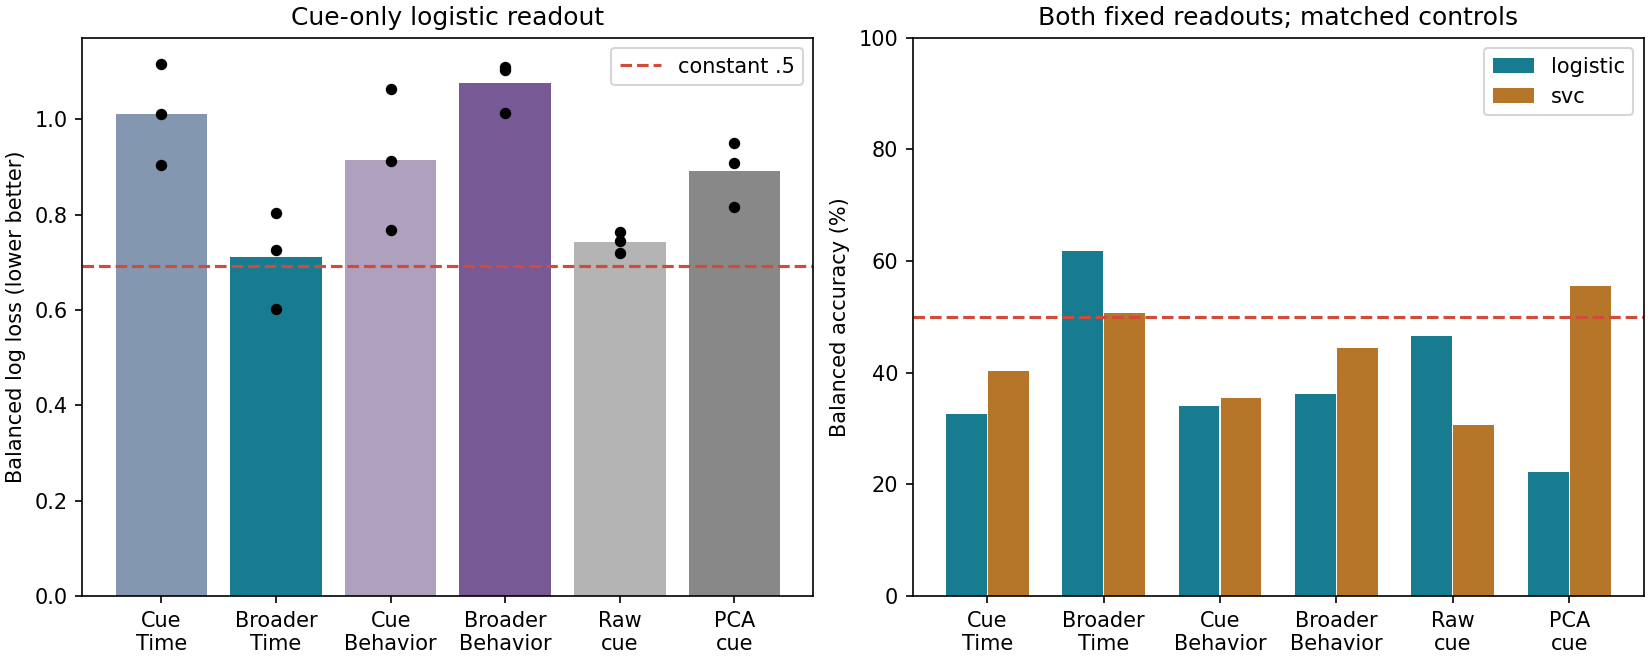


**Figure 5 — Relative improvement beside absolute quality.** September25 fixed-4→3
interior component, 29 units / 7 sessions, 82/22 training/exposed-development sources,
128 training rows and exact 30 development products (24/6, half mass/class). All
readouts receive 0–1 s cue counts: raw/PCA or cue/broader Time/Behavior encoders;
logistic `C=.01` and RBF-SVM `C=1, gamma=scale`. Three paired computational seeds,
not biological replicates. Constant loss `log(2)` and BA .5 anchor interpretation.
**Read it:** broader Time improves relative performance but does not pass the absolute
loss criterion; Behavior differs. Exact image from the accepted
[joint-training report](../docs/reports/cebra-full-trial-transfer/report.html).

## 12. Could a particular cue window explain weak whole-cue decoding?

October5 froze the September25 Time encoders at 1,000 updates and reused PCA, fitting
readouts for every 100-ms cue bin. It performed 5,040 new single-bin readouts across
observed/null worlds and 504 whole-cue replays, with no encoder/PCA refits. This tests
accessible information at each window, not training-duration selection.

Joint-Time logistic reached a descriptive **88.89% BA at 100–200 ms**, versus **61.81%**
whole cue; raw logistic reached **94.44% at 200–300 ms**, versus **46.53%** whole cue.
Whole-cue concatenation changes feature count and effective regularization, so poorer
whole-cue prediction does not prove the brain ignores later activity. Likewise, the
largest inspected peak is not a validated best window or neural-information onset.

The primary maximum joint-gain tail was **9/21**; maximum absolute BA across 80
bin/representation/readout views had tail **17/21**. Many null worlds produced striking
peaks too. These controls prevent promoting the attractive windows to robust H1 evidence.
A decoder fitted separately at every bin is also not temporal transfer: that requires
freezing a decoder trained at one time and applying it at others with all scaling fixed.
Historical raw-LDA goal transfer exists; matched October CEBRA transfer remains absent.
[Full time-readout study](../docs/reports/cebra-cue-time-readout-20261005/README.md).

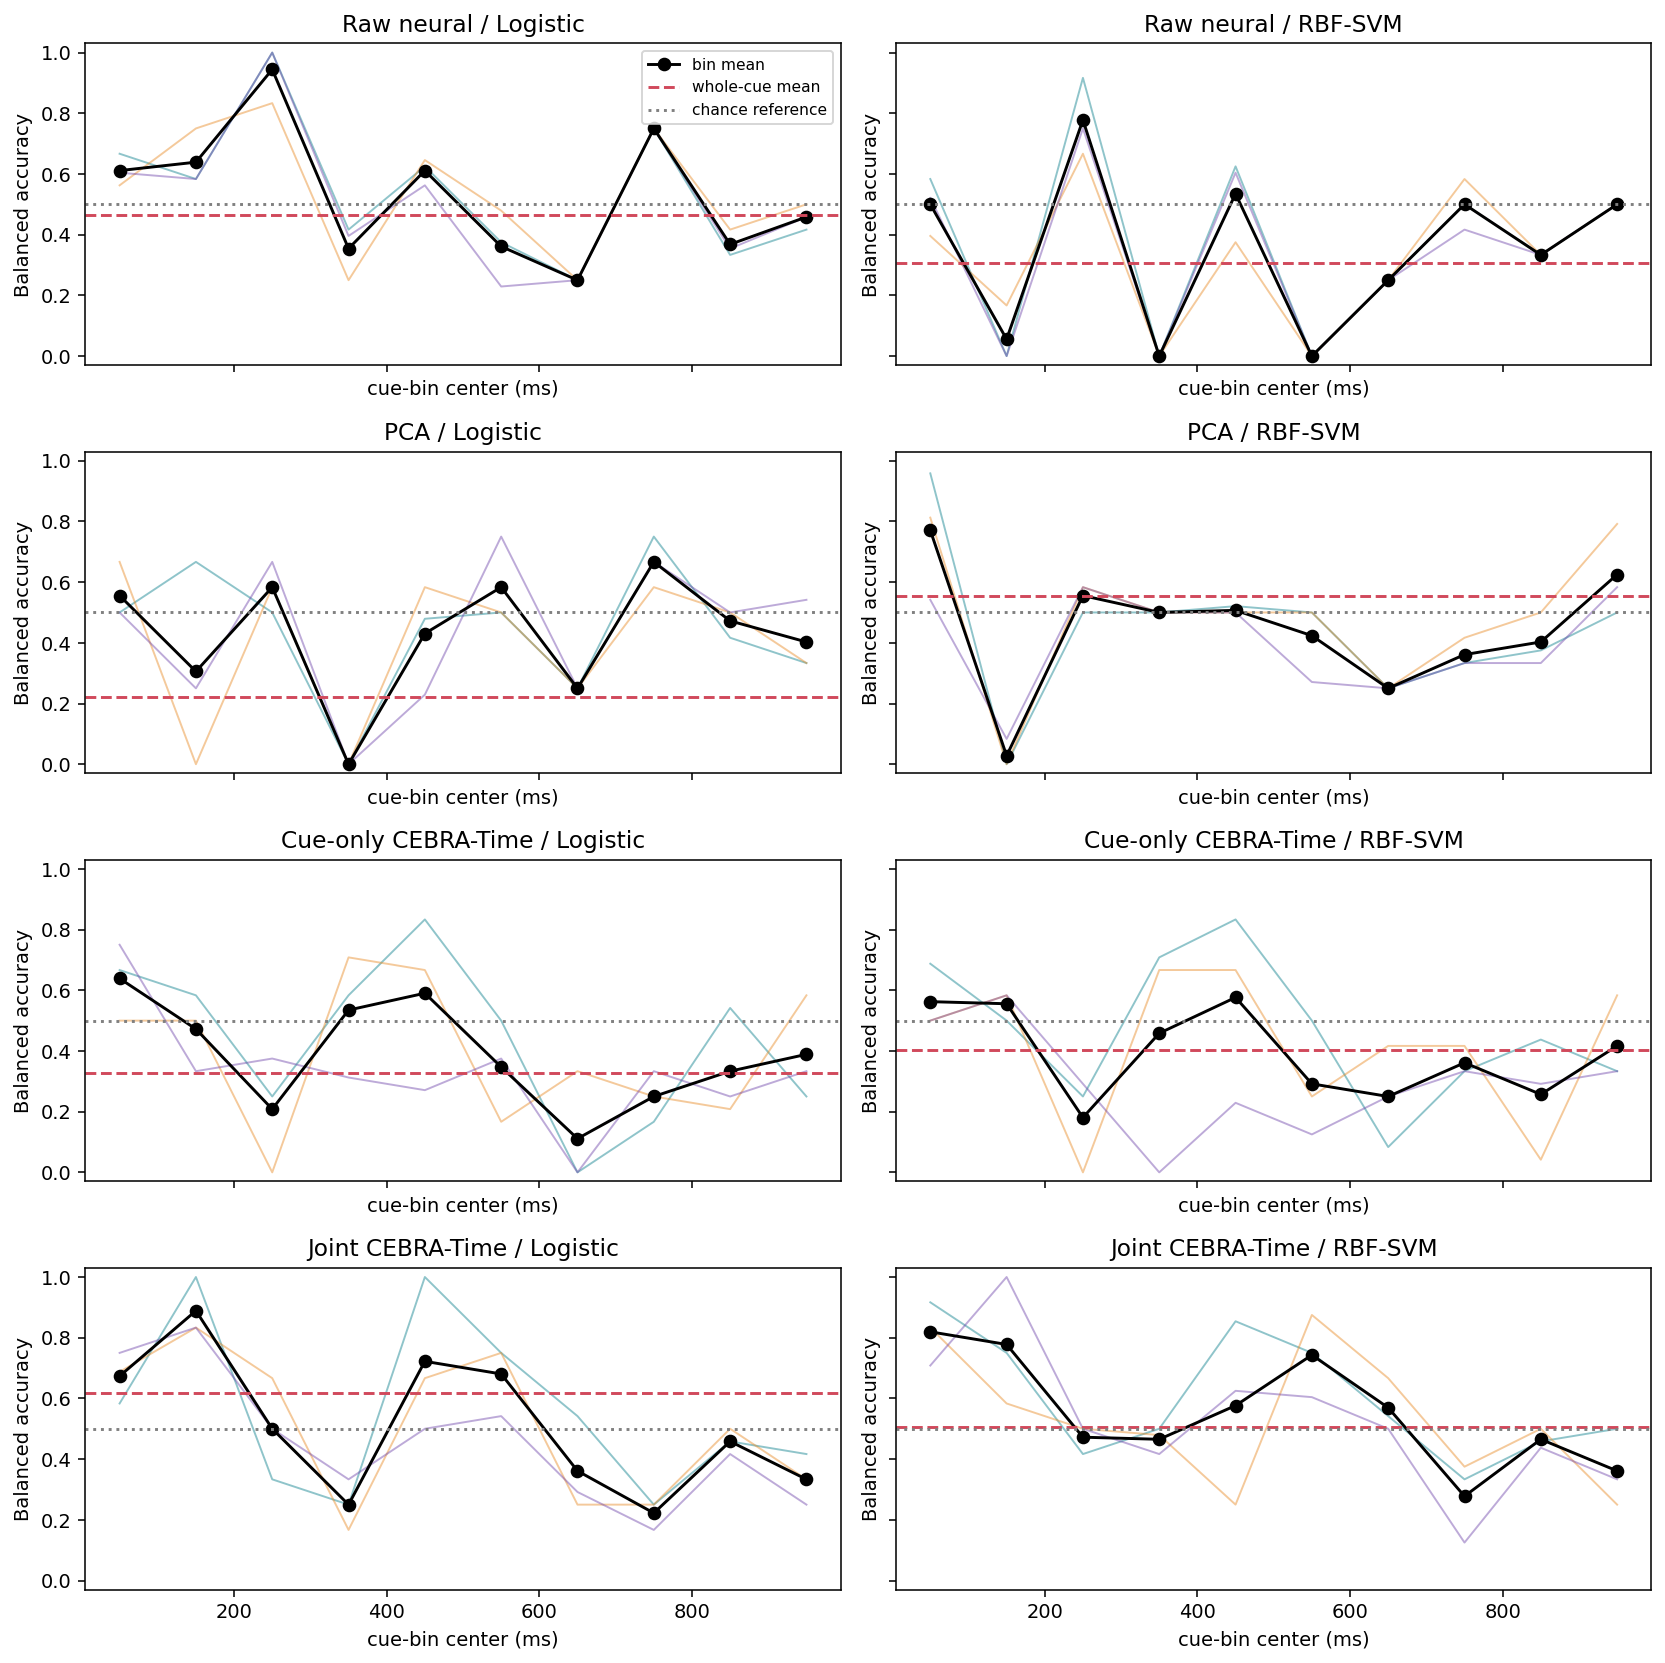


**Figure 6 — Inspect the full curve before naming a peak.** October5 fixed-4→3 target;
29 units / 7 sessions, 82/22 training/exposed-development sources, 128 training rows
and 24/6 exact products, balanced evaluation mass. X is time after cue onset; each
100-ms window has its own logistic or RBF-SVM readout on frozen final-1,000-update
raw/PCA/cue/joint representations. Thin lines are seeds 0–2, black their mean, red
the separately fitted whole-cue result. No biological interval or chosen window.
**Read it:** raw can produce a higher inspected peak than joint CEBRA, and family
controls (17/21 absolute BA; 9/21 joint gain) still limit both. Public original:
[accepted time-readout report](../docs/reports/cebra-cue-time-readout-20261005/README.md).

### Checkpoint geometry is a different measurement again

The same study described saved 250/500/750/1,000-update representations without selecting
a performance checkpoint. Whole-cue development participation ratio changed **3.50→3.99
cue-only** and **2.92→2.79 joint**; training values changed **7.73→5.20** and
**10.05→9.71**. Those are spectra of reused synthetic source combinations, not estimates
of a shared biological manifold. Different train/development support contributes to
the contrast. Distance-rank and neighborhood stability against the final representation
answer whether geometry changes, not whether the state is scientifically identified.

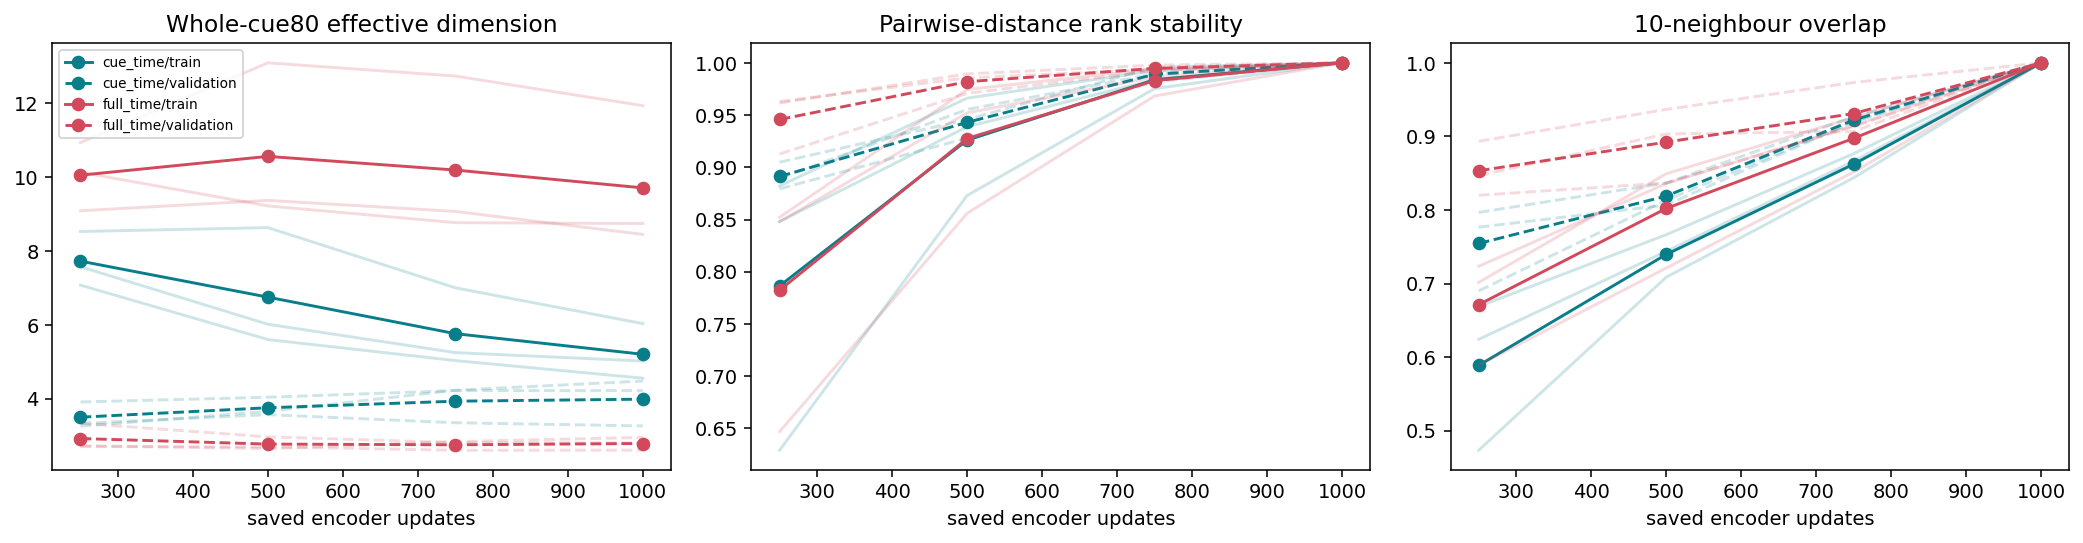


**Figure 7 — Geometry evolves without establishing a better state model.** Observed
saved checkpoints from the joint-path cohort: 29 units / 7 sessions, 82/22 sources,
128 training rows and 30 exact development combinations (24/6). Ten 100-ms cue bins
give 80 CEBRA whole-cue features. Panels show participation ratio, full-space distance
rank correlation and top-ten neighbor overlap against the same rows at 1,000 updates;
final self-comparison equals one by construction. Train/development are separate,
thin lines are computational seeds 0–2, no biological uncertainty. **Read it:** compact
development geometry can coexist with weak source transfer and much richer training
geometry. This is not checkpoint-selected decoding, biological dynamics or H1b.
Original [geometry tables and report](../docs/reports/cebra-cue-time-readout-20261005/README.md).

## 13. What can a successor treat as established, and what is still unavailable?

| Question | Existing evidence | Boundary / unavailable comparison |
| --- | --- | --- |
| Can the conditional populations be assembled? | Explicit support, source lineage, masks and split checks; current Chapter 1 reconstructs compact input | Construction does not establish simultaneity, task semantics or independence |
| Does CEBRA optimize? | Historical endpoint loss/checkpoint traces; finite updates and replay checks | No current compact real-model training curves or convergence certificate here |
| Can representations decode endpoints? | Matched October direct heads, all seeds/windows, BA/loss/confusions | Historically exposed conditions; not unknown-label natural-trial deployment |
| Does nonlinear readout rescue the tested path CEBRA family? | Bounded kNN/logistic/RBF and regularization/kernel diagnosis | No rescue in tested grids; not all decoder/encoder families excluded |
| Is joint training useful? | Matched path and endpoint cue-only readouts; source/null diagnostics | Changes both phase content and cue exposure; no exposure-matched causal isolation |
| Is the geometry three-dimensional or stable? | Older endpoint/V9 atlas and path-checkpoint spectra/fidelity | No identified biological manifold; latest October endpoint joint 3D comparison unavailable |
| Does one readout transfer across time/phase? | Historical raw-LDA goal temporal matrix | Matched October CEBRA cue/joint temporal/cross-phase transfer and navigation decoding unexecuted |
| Is H1 established? | Restricted component assays with explicit negative/uneven evidence | No robust general path finding, full ordered-route reconstruction or H1b demonstration |
| Is hippocampal state observable? | Inspectable computations and task-recovery assays | No explicit validated dynamical/measurement model or formal state-observability result |

The failed/rejected implementation attempts remain in their study ledgers. The early V6
probe's locked-test aggregate exposure was not erased by restarting with guarded access;
the resulting work is development-only. Corrected numerical receipts, no-fit replay and
independent code/claim review improve computational trust, but cannot supply missing lab
metadata or an untouched biological test. Resplitting already inspected data cannot
restore pristine confirmation.

The defensible closure is that these endpoint-fixed/panel studies did **not establish
robust cue-period component/path information**, while exposing source-support constraints
and bounded training/readout effects. That neither refutes hippocampal path coding nor
justifies indefinite tuning until one score looks favorable. H1 remains unresolved; H2
is removed. Pseudopopulations remain legitimate for carefully stated condition-level
questions, and per-unit work remains complementary.

The [future agenda](../docs/cebra-observability-agenda-20261011.md) proposes reusable
readouts and history-based predictive-state estimation. A new study must choose one
independent output/horizon, measurement history, data route, nuisance/baseline controls,
split and success criterion. Same-trial multineuron state claims need verified time-linked
simultaneous observations. A useful compact predictor is not automatically a uniquely
identified neural state. These are research design choices to resolve before another
experiment, not unfinished fits implicitly queued by this chapter.